# Statistiques computationnelles pour le Big Data — chapitres 1 à 3

> Aly DIALLO — codes Python

Ce notebook implémente les méthodes par lots (chapitre 1) et de gradient stochastique (chapitre 2), puis reproduit l'étude de simulation du chapitre 3 (figures 3.1 à 3.7, enregistrées dans `Figures/` sous les noms utilisés par le mémoire).

Dépendances : `numpy`, `scipy`, `matplotlib`, `numba`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

RAPIDE = False   # True : test rapide (M = 1000 itérations, 1 graine) ; False : paramètres du mémoire

## Code commun aux chapitres 3 et 4

Les fonctions ci-dessous (recombinaisons par lots du chapitre 1 et divergence KL) sont **identiques** dans les deux notebooks.

- `consensus_scott` : Algorithme 1 et éq. (1.18), poids $W_s = \widehat{\mathrm{Var}}(\theta_s)^{-1}$ (covariance complète par défaut).
- `neiswanger_parametric` : produit de gaussiennes, éq. (1.17).
- `neiswanger_nonparametric` : Algorithme 2 (Metropolis-within-Gibbs sur les étiquettes $\mathbf L$), poids $\omega_{\mathbf L}$ de l'éq. (1.22), tirage $\theta \sim \mathcal N(\bar\theta_{\mathbf L}, h^2/S\, I)$.
- `neiswanger_semiparametric` : poids $\omega_{\mathbf L}$, composante $\mathcal N(\mu_{\mathbf L}, \Sigma_{\mathbf L})$ de l'éq. (1.25).
- `neiswanger_semiparametric_full` : poids exacts $W_{\mathbf L}$ de l'éq. (1.26), composante (1.25).

Avec recuit, la fenêtre suit $h(j) = h_0\, j^{-1/(4+d)}$ et le poids de l'étiquette courante est recalculé sous $h(j)$ à chaque itération.

**Divergence KL.** Les échantillons MCMC étant autocorrélés, l'estimateur k-NN (conçu pour des tirages i.i.d.) est appliqué après amincissement de chaque échantillon d'un pas égal à son temps d'autocorrélation intégré $\tau$ (`kl_mcmc`). En dimension $d \gtrsim 5$, l'estimateur k-NN devient fortement biaisé (une loi sur-dispersée y reçoit une KL négative) ; on utilise alors la KL entre approximations gaussiennes (`kl_gauss`), justifiée par le théorème de Bernstein-von Mises.

Le code utilise `numba` pour accélérer les boucles (`pip install numba`). Sans `numba`, il s'exécute à l'identique mais beaucoup plus lentement.

In [2]:
# =====================================================================
#  CODE COMMUN AUX CHAPITRES 3 ET 4
#  (recombinaisons par lots du chapitre 1 + estimateur KL k-NN)
#  Ce bloc est STRICTEMENT IDENTIQUE dans les deux notebooks.
# =====================================================================
import numpy as np
from scipy.spatial import cKDTree

try:
    from numba import njit
    NUMBA_OK = True
except ImportError:                     # repli : même code, exécuté en Python pur (lent)
    NUMBA_OK = False
    def njit(*args, **kwargs):
        if len(args) == 1 and callable(args[0]):
            return args[0]
        return lambda f: f

In [3]:
# ---------------------------------------------------------------------
#  Estimateur k-NN de la divergence KL et amincissement des chaînes

In [4]:
# ---------------------------------------------------------------------
def kl_knn(samples_p, samples_q, k=1):
    """KL(P||Q) par k plus proches voisins (Wang, Kulkarni & Verdú, 2009) :
    KL ≈ (d/n) Σ log(ν_k/ρ_k) + log(m/(n-1)).  Suppose des tirages i.i.d."""
    P = np.asarray(samples_p, float)
    Q = np.asarray(samples_q, float)
    if P.ndim == 1:
        P = P[:, None]
    if Q.ndim == 1:
        Q = Q[:, None]
    n, d = P.shape
    m = Q.shape[0]
    rho = cKDTree(P).query(P, k=k + 1)[0][:, k]
    nu = cKDTree(Q).query(P, k=k)[0]
    nu = nu if k == 1 else nu[:, k - 1]
    rho = np.maximum(rho, 1e-300)
    nu = np.maximum(nu, 1e-300)
    return float((d / n) * np.sum(np.log(nu / rho)) + np.log(m / (n - 1)))


def integrated_autocorr_time(x, c=5.0):
    """Temps d'autocorrélation intégré τ (fenêtre automatique de Sokal),
    maximum sur les coordonnées. τ ≈ 1 pour des tirages indépendants."""
    x = np.asarray(x, float)
    if x.ndim == 1:
        x = x[:, None]
    n = x.shape[0]
    if n < 20:
        return 1.0
    xc = x - x.mean(axis=0)
    nfft = 1 << (2 * n - 1).bit_length()
    f = np.fft.rfft(xc, n=nfft, axis=0)
    acf = np.fft.irfft(f * np.conj(f), n=nfft, axis=0)[:n]
    var0 = acf[0]
    ok = var0 > 0
    if not np.any(ok):
        return float(n)               # chaîne figée
    rho = acf[:, ok] / var0[ok]
    taus = 2.0 * np.cumsum(rho, axis=0) - 1.0
    tau_max = 1.0
    for j in range(taus.shape[1]):
        win = np.arange(n) >= c * taus[:, j]
        w = int(np.argmax(win)) if np.any(win) else n - 1
        tau_max = max(tau_max, float(taus[w, j]))
    return tau_max


def thin_chain(x, n_min=200):
    """Amincit un échantillon MCMC d'un pas ⌈τ⌉ (≈ ESS points quasi indépendants),
    en conservant au moins n_min points régulièrement espacés."""
    x = np.asarray(x, float)
    step = max(1, int(np.ceil(integrated_autocorr_time(x))))
    step = min(step, max(1, x.shape[0] // n_min))
    return x[::step]


def kl_mcmc(samples_p, samples_q, n_max=2000, rng=None):
    """KL k-NN adaptée aux sorties MCMC : chaque échantillon est aminci à des
    tirages quasi indépendants (au moins 200 points), puis ramené à au plus n_max points.
    Sans cet amincissement, le plus proche voisin d'un point est son prédécesseur
    dans la chaîne et la KL est artificiellement gonflée. Si la taille effective
    est inférieure à 200, la corrélation résiduelle pénalise la chaîne (mélange lent).
    Les points identiques de P (rejets MH simultanés) sont retirés : ils donneraient
    ρ_k = 0 et une KL infinie."""
    if rng is None:
        rng = np.random.default_rng(0)
    P = np.unique(thin_chain(samples_p), axis=0)   # points identiques (rejets MH) : ρ = 0
    Q = thin_chain(samples_q)
    if P.shape[0] > n_max:
        P = P[rng.choice(P.shape[0], n_max, replace=False)]
    if Q.shape[0] > n_max:
        Q = Q[rng.choice(Q.shape[0], n_max, replace=False)]
    return kl_knn(P, Q)


def kl_gauss(samples_p, samples_q):
    """KL entre les approximations gaussiennes des deux échantillons :
    KL(N(μ_P,Σ_P) || N(μ_Q,Σ_Q)) = ½[tr(Σ_Q⁻¹Σ_P) + (μ_Q-μ_P)ᵀΣ_Q⁻¹(μ_Q-μ_P) - d + log|Σ_Q|/|Σ_P|].
    Utilise tous les points (moyenne et covariance restent consistantes pour une chaîne
    autocorrélée). À privilégier dès d ≳ 5, où l'estimateur k-NN devient fortement biaisé
    (une loi sur-dispersée y reçoit une KL estimée négative)."""
    P = np.asarray(samples_p, float)
    Q = np.asarray(samples_q, float)
    if P.ndim == 1:
        P = P[:, None]
    if Q.ndim == 1:
        Q = Q[:, None]
    d = P.shape[1]
    mp, mq = P.mean(axis=0), Q.mean(axis=0)
    Sp = np.atleast_2d(np.cov(P, rowvar=False))
    Sq = np.atleast_2d(np.cov(Q, rowvar=False))
    iq = np.linalg.inv(Sq)
    dm = mq - mp
    return float(0.5 * (np.trace(iq @ Sp) + dm @ iq @ dm - d
                        + np.linalg.slogdet(Sq)[1] - np.linalg.slogdet(Sp)[1]))

In [5]:
# ---------------------------------------------------------------------
#  Méthodes paramétriques (section 1.4)

In [6]:
# ---------------------------------------------------------------------
def _batch_moments(batch_samples):
    """Moyennes μ̂_s, covariances Σ̂_s et précisions Σ̂_s^{-1} empiriques de chaque lot."""
    S = len(batch_samples)
    d = batch_samples[0].shape[1]
    mu = np.empty((S, d))
    cov = np.empty((S, d, d))
    prec = np.empty((S, d, d))
    for s in range(S):
        mu[s] = batch_samples[s].mean(axis=0)
        cov[s] = np.atleast_2d(np.cov(batch_samples[s], rowvar=False))
        prec[s] = np.linalg.pinv(cov[s])
    return mu, cov, prec


def parametric_product(batch_samples):
    """Produit des approximations gaussiennes (éq. 1.17) :
    Σ̂ = (Σ_s Σ̂_s^{-1})^{-1},  μ̂ = Σ̂ Σ_s Σ̂_s^{-1} μ̂_s.  Renvoie (μ̂, Σ̂, Σ̂^{-1})."""
    mu, cov, prec = _batch_moments(batch_samples)
    prec_tot = prec.sum(axis=0)
    sigma = np.linalg.pinv(prec_tot)
    sigma = 0.5 * (sigma + sigma.T)
    mu_hat = sigma @ np.einsum("sij,sj->i", prec, mu)
    return mu_hat, sigma, prec_tot


def consensus_scott(batch_samples, diagonal=False):
    """Consensus Monte Carlo (Algorithme 1, éq. 1.18) :
    θ̂_j = (Σ_s W_s)^{-1} Σ_s W_s θ_{s,j},  W_s = Var(θ_s)^{-1}.
    diagonal=False : W_s = inverse de la covariance empirique complète du lot ;
    diagonal=True  : W_s = inverse des seules variances marginales."""
    stacked = np.stack(batch_samples, axis=0)                # (S, M, d)
    if diagonal:
        w = 1.0 / np.maximum(stacked.var(axis=1, ddof=1), 1e-300)   # (S, d)
        return np.einsum("sd,smd->md", w, stacked) / w.sum(axis=0)
    _, _, prec = _batch_moments(batch_samples)
    num = np.einsum("sij,smj->mi", prec, stacked)
    return num @ np.linalg.pinv(prec.sum(axis=0)).T


def neiswanger_parametric(batch_samples, n_samples=None, rng=None):
    """Méthode paramétrique de Neiswanger : tirages i.i.d. de N(μ̂, Σ̂) (éq. 1.17)."""
    if rng is None:
        rng = np.random.default_rng()
    n_samples = n_samples or batch_samples[0].shape[0]
    mu_hat, sigma, _ = parametric_product(batch_samples)
    return rng.multivariate_normal(mu_hat, sigma, size=n_samples)

In [7]:
# ---------------------------------------------------------------------
#  Metropolis-within-Gibbs sur les étiquettes L (Algorithme 2)

In [8]:
# ---------------------------------------------------------------------
@njit
def _mwg_labels(samples, sqn, h_seq, cand, logu, labels0, full, logf, mu_hat, V, sig_eig):
    """Échantillonne les étiquettes L = (l_1..l_S) du mélange à M^S composantes.

    Poids non paramétrique (éq. 1.22), à une constante dépendant de h près :
        log ω_L = -(1/2h²) Σ_s ||θ_{l_s,s} - θ̄_L||²
                = -(1/2h²) (Σ_s ||θ_{l_s,s}||² - S ||θ̄_L||²).
    Poids semi-paramétrique complet (éq. 1.26) si full=True :
        log W_L = log ω_L + log N(θ̄_L | μ̂, Σ̂ + h²/S I) - Σ_s log f̂_s(θ_{l_s,s}).
    À chaque itération j, le poids courant est recalculé sous la fenêtre h(j),
    de sorte que le rapport ω_C/ω_L compare deux poids sous la même fenêtre."""
    S, M, d = samples.shape
    T = h_seq.shape[0]
    tbar_out = np.empty((T, d))
    labels = labels0.copy()
    ssum = np.zeros(d)
    newsum = np.zeros(d)
    n_acc = 0
    for j in range(T):
        h2 = h_seq[j] * h_seq[j]
        hs = h2 / S
        # sommes exactes pour l'étiquette courante
        for k in range(d):
            ssum[k] = 0.0
        ssq = 0.0
        slf = 0.0
        for s in range(S):
            l = labels[s]
            ssq += sqn[s, l]
            slf += logf[s, l]
            for k in range(d):
                ssum[k] += samples[s, l, k]
        # log-poids courant sous h(j)
        nrm = 0.0
        for k in range(d):
            nrm += ssum[k] * ssum[k]
        cur = -(ssq - nrm / S) / (2.0 * h2)
        if full:
            q = 0.0
            for a in range(d):
                z = 0.0
                for k in range(d):
                    z += V[k, a] * (ssum[k] / S - mu_hat[k])
                q += z * z / (sig_eig[a] + hs)
            cur += -0.5 * q - slf
        for s in range(S):
            c = cand[j, s]
            old = labels[s]
            if c == old:
                continue
            nssq = ssq - sqn[s, old] + sqn[s, c]
            nrm = 0.0
            for k in range(d):
                newsum[k] = ssum[k] - samples[s, old, k] + samples[s, c, k]
                nrm += newsum[k] * newsum[k]
            lw = -(nssq - nrm / S) / (2.0 * h2)
            nslf = slf - logf[s, old] + logf[s, c]
            if full:
                q = 0.0
                for a in range(d):
                    z = 0.0
                    for k in range(d):
                        z += V[k, a] * (newsum[k] / S - mu_hat[k])
                    q += z * z / (sig_eig[a] + hs)
                lw += -0.5 * q - nslf
            if logu[j, s] < lw - cur:
                labels[s] = c
                ssq = nssq
                slf = nslf
                for k in range(d):
                    ssum[k] = newsum[k]
                cur = lw
                n_acc += 1
        for k in range(d):
            tbar_out[j, k] = ssum[k] / S
    return tbar_out, n_acc


def _run_label_sampler(batch_samples, bandwidth, anneal, n_samples, rng, full):
    stacked = np.ascontiguousarray(np.stack(batch_samples, axis=0), dtype=float)   # (S, M, d)
    S, M, d = stacked.shape
    T = n_samples or M
    h0 = float(bandwidth)
    j = np.arange(1, T + 1, dtype=float)
    h_seq = h0 * j ** (-1.0 / (4.0 + d)) if anneal else np.full(T, h0)   # recuit h(j)
    sqn = np.einsum("smd,smd->sm", stacked, stacked)
    cand = rng.integers(0, M, size=(T, S))
    logu = np.log(rng.uniform(size=(T, S)))
    labels0 = rng.integers(0, M, size=S)
    mu_hat, sigma, prec_tot = parametric_product(batch_samples)
    if full:
        mu_b, cov_b, prec_b = _batch_moments(batch_samples)
        logf = np.empty((S, M))
        for s in range(S):                                   # log f̂_s(θ_{m,s})
            diff = stacked[s] - mu_b[s]
            sign, logdet = np.linalg.slogdet(cov_b[s])
            logf[s] = -0.5 * np.einsum("mi,ij,mj->m", diff, prec_b[s], diff) - 0.5 * logdet
        sig_eig, V = np.linalg.eigh(sigma)
        sig_eig = np.maximum(sig_eig, 1e-300)
    else:
        logf = np.zeros((S, M))
        sig_eig, V = np.ones(d), np.eye(d)
    tbar, n_acc = _mwg_labels(stacked, sqn, h_seq, cand, logu, labels0, bool(full),
                              logf, mu_hat, V, sig_eig)
    return tbar, h_seq, mu_hat, prec_tot, n_acc / (T * S)


def neiswanger_nonparametric(batch_samples, bandwidth, anneal=True, n_samples=None,
                             rng=None, return_acc=False):
    """Méthode non paramétrique (Algorithme 2) : θ_j ~ N(θ̄_L, h(j)²/S · I)."""
    if rng is None:
        rng = np.random.default_rng()
    tbar, h_seq, _, _, acc = _run_label_sampler(batch_samples, bandwidth, anneal,
                                                n_samples, rng, full=False)
    S = len(batch_samples)
    out = tbar + (h_seq / np.sqrt(S))[:, None] * rng.standard_normal(tbar.shape)
    return (out, acc) if return_acc else out


def _semipara_draw(tbar, h_seq, mu_hat, prec_tot, S, rng):
    """Composante (éq. 1.25) : Σ_L = (S/h² I + Σ̂^{-1})^{-1},
    μ_L = Σ_L (S/h² θ̄_L + Σ̂^{-1} μ̂) ; tirage θ_j ~ N(μ_L, Σ_L)."""
    lam, U = np.linalg.eigh(0.5 * (prec_tot + prec_tot.T))
    lam = np.maximum(lam, 0.0)
    kappa = S / h_seq ** 2                                      # (T,)
    inv_eig = 1.0 / (kappa[:, None] + lam[None, :])             # (T, d)
    rhs = kappa[:, None] * tbar + (prec_tot @ mu_hat)[None, :]
    mean = ((rhs @ U) * inv_eig) @ U.T
    noise = (rng.standard_normal(tbar.shape) * np.sqrt(inv_eig)) @ U.T
    return mean + noise


def neiswanger_semiparametric(batch_samples, bandwidth, anneal=True, n_samples=None,
                              rng=None, return_acc=False):
    """Semi-paramétrique (heuristique) : poids non paramétriques ω_L, composante (1.25)."""
    if rng is None:
        rng = np.random.default_rng()
    tbar, h_seq, mu_hat, prec_tot, acc = _run_label_sampler(batch_samples, bandwidth,
                                                            anneal, n_samples, rng, full=False)
    out = _semipara_draw(tbar, h_seq, mu_hat, prec_tot, len(batch_samples), rng)
    return (out, acc) if return_acc else out


def neiswanger_semiparametric_full(batch_samples, bandwidth, anneal=True, n_samples=None,
                                   rng=None, return_acc=False):
    """Semi-paramétrique complet : poids exacts W_L (éq. 1.26), composante (1.25)."""
    if rng is None:
        rng = np.random.default_rng()
    tbar, h_seq, mu_hat, prec_tot, acc = _run_label_sampler(batch_samples, bandwidth,
                                                            anneal, n_samples, rng, full=True)
    out = _semipara_draw(tbar, h_seq, mu_hat, prec_tot, len(batch_samples), rng)
    return (out, acc) if return_acc else out

## Cible du chapitre 3

Localisation $\theta$ d'une loi de Student multivariée : $x_i \sim t_\nu(\theta, \sigma I_d)$ avec $\nu = 3$, $\sigma = 5$, $\theta = 0$, prior plat. La loi a posteriori est $\log p(\theta\mid x) = -\frac{\nu+d}{2}\sum_i \log\!\big(1 + \lVert x_i-\theta\rVert^2/(\nu\sigma)\big) + \text{cte}$.

- MH : proposition isotrope, échelle adaptée pendant le burn-in (cible 25 %) puis gelée.
- SGLD (Algorithme 3) : $\epsilon_t = (a/N)(1+t)^{-1/3}$.
- SGHMC (Algorithme 4) : moment ré-injecté à chaque itération, nouveau mini-lot à chaque pas, $\eta = \gamma/N$, $\hat\beta = 0$.
- Approximation de Laplace stochastique : SGD (éq. 2.2) puis $\mathcal N(\theta^*, (-H)^{-1})$.

Les mini-lots sont tirés uniformément avec remise, ce qui correspond exactement à l'hypothèse de la preuve de l'estimateur sans biais (2.13).

In [9]:
# =====================================================================
#  CIBLE DU CHAPITRE 3 : localisation d'une Student-t multivariée
#  x_i ~ t_ν(θ, σ·I_d), ν = 3, σ = 5 ; prior plat sur θ.
#  log p(θ|x) = -(ν+d)/2 Σ_i log(1 + ||x_i-θ||²/(νσ)) + cte
# =====================================================================
from scipy.stats import multivariate_t

NU = 3.0
SIGMA_SCALE = 5.0


def generate_data(n_obs, dimension, rng, nu=NU, sigma_scale=SIGMA_SCALE):
    """N observations i.i.d. de t_ν(0, σ I_d)."""
    return multivariate_t.rvs(loc=np.zeros(dimension), shape=sigma_scale * np.eye(dimension),
                              df=nu, size=n_obs,
                              random_state=int(rng.integers(2**31 - 1))).reshape(n_obs, dimension)


@njit
def log_lik(X, theta, nu, sig):
    """Log-vraisemblance Student-t (à constante près)."""
    n, d = X.shape
    tot = 0.0
    for i in range(n):
        q = 0.0
        for k in range(d):
            u = X[i, k] - theta[k]
            q += u * u
        tot += np.log1p(q / (nu * sig))
    return -0.5 * (nu + d) * tot


@njit
def grad_log_lik_idx(X, idx, theta, nu, sig, out):
    """Σ_{i∈idx} ∇_θ log p(x_i|θ) = Σ (ν+d)/(νσ) (x_i-θ) / (1 + ||x_i-θ||²/(νσ))."""
    d = X.shape[1]
    c = (nu + d) / (nu * sig)
    for k in range(d):
        out[k] = 0.0
    for r in range(idx.shape[0]):
        i = idx[r]
        q = 0.0
        for k in range(d):
            u = X[i, k] - theta[k]
            q += u * u
        w = c / (1.0 + q / (nu * sig))
        for k in range(d):
            out[k] += w * (X[i, k] - theta[k])


def grad_log_lik(X, theta, nu=NU, sig=SIGMA_SCALE):
    """Gradient exact de la log-vraisemblance (toutes les observations)."""
    out = np.zeros(X.shape[1])
    grad_log_lik_idx(X, np.arange(X.shape[0]), np.asarray(theta, float), nu, sig, out)
    return out


def hessian_log_lik(X, theta, nu=NU, sig=SIGMA_SCALE):
    """Hessienne exacte de la log-vraisemblance (utilisée par l'approximation de Laplace)."""
    d = X.shape[1]
    diff = X - theta
    q = 1.0 + np.einsum("ij,ij->i", diff, diff) / (nu * sig)
    c = (nu + d) / (nu * sig)
    outer = np.einsum("i,ij,ik->jk", 1.0 / q ** 2, diff, diff)
    return -c * (1.0 / q).sum() * np.eye(d) + (2.0 * c / (nu * sig)) * outer

In [10]:
# ---------------------------------------------------------------------
#  Metropolis-Hastings (référence et sous-lois a posteriori)

In [11]:
# ---------------------------------------------------------------------
@njit
def _mh_kernel(X, theta0, scale0, Z, logu, burn_in, target, nu, sig):
    T, d = Z.shape
    theta = theta0.copy()
    prop = np.empty(d)
    lp = log_lik(X, theta, nu, sig)
    out = np.empty((T - burn_in, d))
    scale = scale0
    win = 0
    n_acc = 0
    for i in range(T):
        for k in range(d):
            prop[k] = theta[k] + scale * Z[i, k]
        lpp = log_lik(X, prop, nu, sig)
        if logu[i] < lpp - lp:
            for k in range(d):
                theta[k] = prop[k]
            lp = lpp
            win += 1
            if i >= burn_in:
                n_acc += 1
        if i < burn_in and (i + 1) % 100 == 0:          # adaptation pendant le burn-in seulement
            scale *= np.exp(win / 100.0 - target)
            win = 0
        if i >= burn_in:
            for k in range(d):
                out[i - burn_in, k] = theta[k]
    return out, n_acc / max(T - burn_in, 1)


def mh_sampler(X, n_samples, burn_in, rng, theta_init=None, target_acc=0.25,
               return_acc=False):
    """MH à proposition gaussienne isotrope. L'échelle part de 2.4/sqrt(N d), est adaptée
    pendant le burn-in (cible 25 % d'acceptation) puis gelée : la chaîne conservée
    est un MH homogène qui laisse invariante p(θ|x). Prior plat."""
    N, d = X.shape
    theta0 = np.zeros(d) if theta_init is None else np.asarray(theta_init, float)
    T = burn_in + n_samples
    Z = rng.standard_normal((T, d))
    logu = np.log(rng.uniform(size=T))
    out, acc = _mh_kernel(np.ascontiguousarray(X, float), theta0, 2.4 / np.sqrt(N * d),
                          Z, logu, burn_in, target_acc, NU, SIGMA_SCALE)
    return (out, acc) if return_acc else out


def partition_data(X, n_batches, rng):
    """Partition aléatoire en S lots (définition 1.1)."""
    return [X[i] for i in np.array_split(rng.permutation(X.shape[0]), n_batches)]


def mh_sub_posteriors(batches, n_samples, burn_in, rng):
    """Sous-lois a posteriori p_s(θ) ∝ p(θ)^{1/S} p(x_{B_s}|θ) (définition 1.2).
    Le prior étant plat, la puissance 1/S est sans effet."""
    return [mh_sampler(b, n_samples, burn_in, rng) for b in batches]

In [12]:
# ---------------------------------------------------------------------
#  SGLD (Algorithme 3) et SGHMC (Algorithme 4)
#  Les mini-lots sont tirés uniformément (avec remise), ce qui correspond
#  exactement à l'hypothèse de la preuve de l'estimateur sans biais (2.13).

In [13]:
# ---------------------------------------------------------------------
@njit
def _sgld_chunk(X, theta, idx, noise, eps, nu, sig, out, t0):
    N = X.shape[0]
    n = idx.shape[1]
    d = theta.shape[0]
    g = np.empty(d)
    for t in range(idx.shape[0]):
        grad_log_lik_idx(X, idx[t], theta, nu, sig, g)
        e = eps[t]
        for k in range(d):
            theta[k] += 0.5 * e * (N / n) * g[k] + np.sqrt(e) * noise[t, k]
            out[t0 + t, k] = theta[k]


def sgld_sampler(X, n_iter, subsample_size, step_const, rng, theta_init=None):
    """SGLD : θ ← θ + (ε_t/2) ∇log p̃(θ) + N(0, ε_t),  ε_t = (a/N)(1+t)^{-1/3}."""
    N, d = X.shape
    theta = np.zeros(d) if theta_init is None else np.asarray(theta_init, float).copy()
    out = np.empty((n_iter, d))
    eps_all = step_const / N * (np.arange(n_iter) + 1.0) ** (-1.0 / 3.0)
    chunk = max(1, 2_000_000 // subsample_size)
    Xc = np.ascontiguousarray(X, float)
    for t0 in range(0, n_iter, chunk):
        t1 = min(n_iter, t0 + chunk)
        idx = rng.integers(0, N, size=(t1 - t0, subsample_size))
        noise = rng.standard_normal((t1 - t0, d))
        _sgld_chunk(Xc, theta, idx, noise, eps_all[t0:t1], NU, SIGMA_SCALE, out, t0)
    return out


@njit
def _sghmc_chunk(X, theta, idx, v0, noise, eta, alpha, noise_std, nu, sig, out, t0):
    N = X.shape[0]
    T, L, n = idx.shape
    d = theta.shape[0]
    g = np.empty(d)
    v = np.empty(d)
    for t in range(T):
        for k in range(d):
            v[k] = np.sqrt(eta) * v0[t, k]                 # r ~ N(0, M), ν = ε M^{-1} r
        for l in range(L):
            grad_log_lik_idx(X, idx[t, l], theta, nu, sig, g)   # nouveau mini-lot à chaque pas
            for k in range(d):
                v[k] = (1.0 - alpha) * v[k] + eta * (N / n) * g[k] + noise_std * noise[t, l, k]
                theta[k] += v[k]
        for k in range(d):
            out[t0 + t, k] = theta[k]


def sghmc_sampler(X, n_iter, subsample_size, alpha, eta, trajectory_length, rng,
                  beta_hat=0.0, theta_init=None):
    """SGHMC (Algorithme 4) : ré-injection du moment à chaque itération externe,
    puis L pas  ν ← (1-α)ν - η∇Ũ(θ) + N(0, 2(α-β̂)η),  θ ← θ + ν."""
    if alpha < beta_hat:
        raise ValueError("alpha doit être >= beta_hat")
    N, d = X.shape
    theta = np.zeros(d) if theta_init is None else np.asarray(theta_init, float).copy()
    out = np.empty((n_iter, d))
    L = trajectory_length
    noise_std = np.sqrt(2.0 * (alpha - beta_hat) * eta)
    chunk = max(1, 2_000_000 // (subsample_size * L))
    Xc = np.ascontiguousarray(X, float)
    for t0 in range(0, n_iter, chunk):
        t1 = min(n_iter, t0 + chunk)
        idx = rng.integers(0, N, size=(t1 - t0, L, subsample_size))
        v0 = rng.standard_normal((t1 - t0, d))
        noise = rng.standard_normal((t1 - t0, L, d))
        _sghmc_chunk(Xc, theta, idx, v0, noise, eta, alpha, noise_std, NU, SIGMA_SCALE, out, t0)
    return out


def stochastic_approx_sampler(X, n_samples, rng, n_sgd_iter=2000, subsample_size=100,
                              step_const=0.5):
    """Approximation de Laplace stochastique : SGD (éq. 2.2) vers le mode θ*,
    puis N(θ*, (-H(θ*))^{-1}) (proposition de la section 2.2.1)."""
    N, d = X.shape
    n = min(subsample_size, N)
    theta = np.zeros(d)
    out = np.empty((n_sgd_iter, d))
    eps = step_const / N * (np.arange(n_sgd_iter) + 1.0) ** (-1.0 / 3.0)
    idx = rng.integers(0, N, size=(n_sgd_iter, n))
    _sgld_chunk(np.ascontiguousarray(X, float), theta, idx, np.zeros((n_sgd_iter, d)),
                eps, NU, SIGMA_SCALE, out, 0)                 # SGLD sans bruit = SGD
    cov = np.linalg.pinv(-hessian_log_lik(X, theta))
    cov = 0.5 * (cov + cov.T)
    return rng.multivariate_normal(theta, cov, size=n_samples)

## Vérifications numériques des résultats théoriques

In [14]:
import itertools
from scipy.stats import multivariate_normal as mvn, norm

rng = np.random.default_rng(7)

# 1) Gradient et Hessienne de la log-vraisemblance Student-t vs différences finies
X = generate_data(50, 3, rng)
th, e = 0.5 * rng.normal(size=3), 1e-6
E3 = np.eye(3)
g_num = np.array([(log_lik(X, th + e * E3[j], NU, SIGMA_SCALE)
                   - log_lik(X, th - e * E3[j], NU, SIGMA_SCALE)) / (2 * e) for j in range(3)])
H_num = np.column_stack([(grad_log_lik(X, th + e * E3[j]) - grad_log_lik(X, th - e * E3[j])) / (2 * e)
                         for j in range(3)])
print(f"1) |Δgradient| = {np.abs(g_num - grad_log_lik(X, th)).max():.1e} ; "
      f"|ΔHessienne| = {np.abs(H_num - hessian_log_lik(X, th)).max():.1e}")

# 2) Estimateur sans biais du gradient (éq. 2.13)
X = generate_data(400, 2, rng)
th = np.array([0.3, -0.2])
g_full = grad_log_lik(X, th)
g_hat = np.mean([(400 / 40) * grad_log_lik(X[rng.integers(0, 400, 40)], th) for _ in range(20000)], axis=0)
print(f"2) écart relatif E[∇Ũ] / ∇U = {np.linalg.norm(g_hat - g_full) / np.linalg.norm(g_full):.4f}")

# 3) Bernstein-von Mises : écart-type a posteriori ≈ (N I(θ))^{-1/2}, I = (ν+d)/((ν+d+2)σ)
X = generate_data(2000, 2, np.random.default_rng(11))
s = mh_sampler(X, 40_000, 2_000, np.random.default_rng(12))
I_f = (NU + 2) / ((NU + 4) * SIGMA_SCALE)
print(f"3) écart-type MH / (N I)^(-1/2) = {s.std(axis=0).mean() * np.sqrt(2000 * I_f):.3f}")

# 4) Produit de gaussiennes (éq. 1.17) : Scott et NeisPara sont exacts si les sous-lois sont gaussiennes
S_, d_ = 4, 2
mus = [rng.normal(size=d_) for _ in range(S_)]
covs = [(lambda A: A @ A.T + 0.5 * np.eye(d_))(rng.normal(size=(d_, d_))) for _ in range(S_)]
bs = [rng.multivariate_normal(mus[k], covs[k], 20000) for k in range(S_)]
Sig = np.linalg.inv(sum(np.linalg.inv(c) for c in covs))
mu = Sig @ sum(np.linalg.inv(covs[k]) @ mus[k] for k in range(S_))
for name, x in [("Scott", consensus_scott(bs)), ("NeisPara", neiswanger_parametric(bs, rng=rng))]:
    print(f"4) {name:8s} |Δμ| = {np.linalg.norm(x.mean(0) - mu):.3f}  "
          f"|ΔΣ| = {np.linalg.norm(np.cov(x, rowvar=False) - Sig):.3f}")

# 5) Algorithme 2 : les étiquettes suivent exactement les poids ω_L (1.22) et W_L (1.26)
S_, M_, h = 3, 4, 0.8
bs = [0.7 * rng.normal(size=(M_, 2)) + 0.3 * k for k in range(S_)]
stk = np.stack(bs)
mu_b, cov_b, _ = _batch_moments(bs)
mu_h, sig_h, _ = parametric_product(bs)
labs = [np.array(L) for L in itertools.product(range(M_), repeat=S_)]
means = np.array([stk[np.arange(S_), L].mean(0) for L in labs])
for full in (False, True):
    lw = []
    for L, tb in zip(labs, means):
        tv = stk[np.arange(S_), L]
        w = norm.logpdf(tv, tb, h).sum()
        if full:
            w += mvn.logpdf(tb, mu_h, sig_h + h**2 / S_ * np.eye(2)) \
                 - sum(mvn.logpdf(tv[k], mu_b[k], cov_b[k]) for k in range(S_))
        lw.append(w)
    p = np.exp(np.array(lw) - max(lw)); p /= p.sum()
    tbar = _run_label_sampler(bs, h, False, 200_000, np.random.default_rng(2), full)[0]
    freq = np.bincount(cKDTree(means).query(tbar)[1], minlength=len(labs)) / len(tbar)
    print(f"5) poids {'W_L (1.26)' if full else 'ω_L (1.22)'} : variation totale "
          f"fréquences / poids exacts = {0.5 * np.abs(freq - p).sum():.4f}")

# 6) Divergence KL : effet de l'autocorrélation et de la dimension (d = 10)
d_ = 10
ref = rng.normal(size=(20000, d_))
x, ch = np.zeros(d_), np.empty((20000, d_))                 # MH aléatoire ciblant N(0, I)
for i in range(20000):
    p = x + 2.38 / np.sqrt(d_) * rng.normal(size=d_)
    if np.log(rng.uniform()) < -0.5 * p @ p + 0.5 * x @ x:
        x = p
    ch[i] = x
print(f"6) chaîne MH de loi N(0, I_10), KL vraie = 0 : k-NN brut = {kl_knn(ch, ref):.0f} ; "
      f"k-NN aminci = {kl_mcmc(ch, ref):.2f} ; gaussienne = {kl_gauss(ch, ref):.2f}")
P = 1.2 * rng.normal(size=(4000, d_))
print(f"   loi sur-dispersée 1.2·N(0, I_10), KL vraie = {0.5 * d_ * (0.44 - 2 * np.log(1.2)):.2f} : "
      f"k-NN = {kl_knn(P, ref[:4000]):.2f} ; gaussienne = {kl_gauss(P, ref):.2f}")

1) |Δgradient| = 2.4e-08 ; |ΔHessienne| = 1.0e-09
2) écart relatif E[∇Ũ] / ∇U = 0.0047


3) écart-type MH / (N I)^(-1/2) = 1.000
4) Scott    |Δμ| = 0.009  |ΔΣ| = 0.005
4) NeisPara |Δμ| = 0.010  |ΔΣ| = 0.007


5) poids ω_L (1.22) : variation totale fréquences / poids exacts = 0.0082
5) poids W_L (1.26) : variation totale fréquences / poids exacts = 0.0071


6) chaîne MH de loi N(0, I_10), KL vraie = 0 : k-NN brut = 6467 ; k-NN aminci = -0.11 ; gaussienne = 0.03
   loi sur-dispersée 1.2·N(0, I_10), KL vraie = 0.38 : k-NN = -0.17 ; gaussienne = 0.38


## Étude de simulation (chapitre 3)

In [15]:
# =====================================================================
#  EXPÉRIENCES DU CHAPITRE 3
# =====================================================================
import os
import time
import matplotlib.pyplot as plt

OUTPUT_DIR = "Figures"                 # mêmes noms de fichiers que dans le mémoire
os.makedirs(OUTPUT_DIR, exist_ok=True)
MASTER_SEED = 42
N_SEEDS = 3                            # répétitions indépendantes par point de grille
M_MCMC = 10_000                        # itérations MCMC conservées par chaîne
BURN_IN = 1_000
REF_FACTOR = 10                        # la chaîne MH de référence est 10 fois plus longue
RESULTS = {}

COLORS = {"NeisNonparaAn": "tab:red", "NeisPara": "goldenrod", "NeisSemiparaAn": "tab:green",
          "NeisSemiparaFullAn": "darkcyan", "Scott": "tab:blue", "stochastic_approx": "magenta",
          "SGLD": "tab:purple", "SGHMC": "crimson",
          "Npara": "tab:red", "Semipara": "tab:green", "Semipara_full": "tab:blue"}


def seed_rng(*keys):
    return np.random.default_rng([MASTER_SEED, *[int(k) for k in keys]])


def mh_reference(X, rng, factor=None):
    return mh_sampler(X, (factor or REF_FACTOR) * M_MCMC, 2 * BURN_IN, rng)


def batch_kl(batch_samples, ref, rng, methods, bw_npara, bw_semi, data=None, metric="knn"):
    """KL de chaque méthode par lots par rapport à la référence MH
    (metric="knn" : k-NN aminci, cibles de petite dimension ; "gauss" : KL gaussienne)."""
    out = {}
    for m in methods:
        if m == "Scott":
            x = consensus_scott(batch_samples)
        elif m == "NeisPara":
            x = neiswanger_parametric(batch_samples, rng=rng)
        elif m == "NeisNonparaAn":
            x = neiswanger_nonparametric(batch_samples, bw_npara, True, rng=rng)
        elif m == "NeisSemiparaAn":
            x = neiswanger_semiparametric(batch_samples, bw_semi, True, rng=rng)
        elif m == "NeisSemiparaFullAn":
            x = neiswanger_semiparametric_full(batch_samples, bw_semi, True, rng=rng)
        elif m == "stochastic_approx":
            x = stochastic_approx_sampler(data, M_MCMC, rng)
        out[m] = kl_mcmc(x, ref, rng=rng) if metric == "knn" else kl_gauss(x, ref)
    return out


def plot_curves(grid, res, methods, xlabel, fname, title, ax=None, xlog=False, ylog=False,
                ylabel="Divergence KL"):
    """Moyenne sur les graines (courbes sans bande ombrée)."""
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(9, 5))
    for m in methods:
        vals = np.array(res[m])                       # (n_grid, n_seeds)
        mu, sd = vals.mean(axis=1), vals.std(axis=1)
        ax.plot(grid, mu, marker="o", lw=2, color=COLORS[m], label=m)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if xlog:
        ax.set_xscale("log")
    if ylog:
        ax.set_yscale("symlog", linthresh=0.1)
    ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(title="méthode", fontsize=9)
    if own:
        fig.tight_layout()
        fig.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
        plt.show()


def summary_table(grid, res, methods, label):
    print(f"{label:>10s} | " + " | ".join(f"{m[:14]:>14s}" for m in methods))
    for i, g in enumerate(grid):
        print(f"{g:>10} | " + " | ".join(
            f"{np.mean(res[m][i]):6.3f}±{np.std(res[m][i]):5.3f}" for m in methods))

if RAPIDE:
    M_MCMC, BURN_IN, N_SEEDS = 1_000, 200, 1

In [16]:
# ---------------------------------------------------------------------
#  Figure 3.1 : choix de la fenêtre

In [17]:
# ---------------------------------------------------------------------
def run_figure_3_1(n_obs=1000, n_batches=50, d=2, ratios=(0.5, 0.7, 1.0, 1.2, 1.5, 2.0, 3.0, 4.0)):
    t0 = time.time()
    fns = {"Npara": neiswanger_nonparametric, "Semipara": neiswanger_semiparametric,
           "Semipara_full": neiswanger_semiparametric_full}
    res = {c: {m: [[] for _ in ratios] for m in fns} for c in ("Annealed", "Not Annealed")}
    acc = {c: {m: [[] for _ in ratios] for m in fns} for c in ("Annealed", "Not Annealed")}
    for seed in range(N_SEEDS):
        rng = seed_rng(31, seed)
        X = generate_data(n_obs, d, rng)
        ref = mh_reference(X, rng)
        bs = mh_sub_posteriors(partition_data(X, n_batches, rng), M_MCMC, BURN_IN, rng)
        max_std = max(b.std(axis=0).max() for b in bs)
        for i, r in enumerate(ratios):
            for cond, ann in (("Annealed", True), ("Not Annealed", False)):
                for m, f in fns.items():
                    x, a = f(bs, r * max_std, ann, rng=rng, return_acc=True)
                    res[cond][m][i].append(kl_mcmc(x, ref, rng=rng))
                    acc[cond][m][i].append(a)
    fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
    for ax, cond in zip(axes, res):
        plot_curves(list(ratios), res[cond], list(fns), "", None,
                    "Avec recuit" if cond == "Annealed" else "Sans recuit", ax=ax)
    axes[-1].set_xlabel("Rapport de la fenêtre au plus grand écart-type des lots")
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, "Fig 1.png"), dpi=150)
    plt.show()
    for cond in res:
        print(f"--- {cond} (KL moyenne ± écart-type ; taux d'acceptation des étiquettes)")
        summary_table(list(ratios), res[cond], list(fns), "ratio")
        print("   acceptation :", {m: [round(float(v), 3) for v in np.mean(acc[cond][m], axis=1)] for m in fns})
    RESULTS["fig3_1"] = {"ratios": list(ratios), "kl": res, "acc": acc}
    print(f"[Fig 3.1] {time.time() - t0:.0f} s")

In [18]:
# ---------------------------------------------------------------------
#  Figures 3.2 à 3.4 : méthodes par lots

In [19]:
# ---------------------------------------------------------------------
BATCH_METHODS = ["NeisNonparaAn", "NeisPara", "NeisSemiparaAn", "NeisSemiparaFullAn",
                 "Scott", "stochastic_approx"]
BW_NPARA, BW_SEMI = 1.2, 2.0           # fenêtres initiales retenues (en unités de max_std)


def _batch_point(X, n_batches, rng, metric="knn"):
    ref = mh_reference(X, rng)
    bs = mh_sub_posteriors(partition_data(X, n_batches, rng), M_MCMC, BURN_IN, rng)
    max_std = max(b.std(axis=0).max() for b in bs)
    return batch_kl(bs, ref, rng, BATCH_METHODS, BW_NPARA * max_std, BW_SEMI * max_std, X, metric)


def run_figure_3_2(n_grid=(20, 50, 100, 200, 500, 1000, 2000), n_batches=10, d=2):
    t0 = time.time()
    res = {m: [[] for _ in n_grid] for m in BATCH_METHODS}
    for i, n in enumerate(n_grid):
        for seed in range(N_SEEDS):
            rng = seed_rng(32, n, seed)
            kl = _batch_point(generate_data(n, d, rng), n_batches, rng)
            for m in BATCH_METHODS:
                res[m][i].append(kl[m])
    plot_curves(list(n_grid), res, BATCH_METHODS, "Nombre d'observations N", "Fig 2.png",
                f"Méthodes par lots : S = {n_batches} lots, d = {d}", xlog=True)
    summary_table(list(n_grid), res, BATCH_METHODS, "N")
    RESULTS["fig3_2"] = {"grid": list(n_grid), "kl": res}
    print(f"[Fig 3.2] {time.time() - t0:.0f} s")


def run_figure_3_3(n_obs=800, batch_sizes=(4, 8, 16, 25, 50, 100, 200, 400), d=2):
    t0 = time.time()
    res = {m: [[] for _ in batch_sizes] for m in BATCH_METHODS}
    for i, b in enumerate(batch_sizes):
        for seed in range(N_SEEDS):
            rng = seed_rng(33, b, seed)
            kl = _batch_point(generate_data(n_obs, d, rng), n_obs // b, rng)
            for m in BATCH_METHODS:
                res[m][i].append(kl[m])
    plot_curves(list(batch_sizes), res, BATCH_METHODS, "Taille des lots N/S", "Fig 3.png",
                f"Méthodes par lots : N = {n_obs}, d = {d}", xlog=True)
    summary_table(list(batch_sizes), res, BATCH_METHODS, "N/S")
    RESULTS["fig3_3"] = {"grid": list(batch_sizes), "kl": res}
    print(f"[Fig 3.3] {time.time() - t0:.0f} s")


def run_figure_3_4(n_obs=800, n_batches=40, dims=(2, 4, 6, 8, 10, 12, 16, 20)):
    t0 = time.time()
    res = {m: [[] for _ in dims] for m in BATCH_METHODS}
    for i, d in enumerate(dims):
        for seed in range(N_SEEDS):
            rng = seed_rng(34, d, seed)
            kl = _batch_point(generate_data(n_obs, d, rng), n_batches, rng, metric="gauss")
            for m in BATCH_METHODS:
                res[m][i].append(kl[m])
    plot_curves(list(dims), res, BATCH_METHODS, "Dimension d de la cible", "Fig 4.png",
                f"Méthodes par lots : N = {n_obs}, S = {n_batches} lots de {n_obs // n_batches}",
                ylabel="Divergence KL (approximation gaussienne)")
    summary_table(list(dims), res, BATCH_METHODS, "d")
    RESULTS["fig3_4"] = {"grid": list(dims), "kl": res}
    print(f"[Fig 3.4] {time.time() - t0:.0f} s")

In [20]:
# ---------------------------------------------------------------------
#  Calibrage et figures 3.5 à 3.7 : gradient stochastique

In [21]:
# ---------------------------------------------------------------------
SGHMC_L = 10
SGLD_A, SGHMC_GAMMA, SGHMC_ALPHA = 1.0, 0.05, 0.05      # remplacés par le calibrage


def run_sg(X, n_sub, rng):
    N = X.shape[0]
    n_sub = min(n_sub, N)
    sgld = sgld_sampler(X, BURN_IN + M_MCMC, n_sub, SGLD_A, rng)[BURN_IN:]
    sghmc = sghmc_sampler(X, BURN_IN + M_MCMC, n_sub, SGHMC_ALPHA, SGHMC_GAMMA / N,
                          SGHMC_L, rng)[BURN_IN:]
    return sgld, sghmc


def run_calibration(n_obs=10_000, d=2, n_sub=100, a_grid=(0.1, 0.5, 1, 2, 5, 10, 20),
                    gamma_grid=(0.01, 0.05, 0.1, 0.5), alpha_grid=(0.01, 0.05, 0.1, 0.5)):
    """Choix empirique des constantes en minimisant la KL par rapport à MH (section 3.3.1)."""
    global SGLD_A, SGHMC_GAMMA, SGHMC_ALPHA
    t0 = time.time()
    kl_a = np.zeros((len(a_grid), N_SEEDS))
    kl_h = np.zeros((len(gamma_grid), len(alpha_grid), N_SEEDS))
    for seed in range(N_SEEDS):
        rng = seed_rng(35, seed)
        X = generate_data(n_obs, d, rng)
        ref = mh_reference(X, rng)
        for i, a in enumerate(a_grid):
            x = sgld_sampler(X, BURN_IN + M_MCMC, n_sub, a, rng)[BURN_IN:]
            kl_a[i, seed] = kl_mcmc(x, ref, rng=rng)
        for i, g in enumerate(gamma_grid):
            for j, al in enumerate(alpha_grid):
                x = sghmc_sampler(X, BURN_IN + M_MCMC, n_sub, al, g / n_obs, SGHMC_L, rng)[BURN_IN:]
                kl_h[i, j, seed] = kl_mcmc(x, ref, rng=rng)
    SGLD_A = float(a_grid[int(np.argmin(kl_a.mean(axis=1)))])
    i, j = np.unravel_index(np.argmin(kl_h.mean(axis=2)), kl_h.shape[:2])
    SGHMC_GAMMA, SGHMC_ALPHA = float(gamma_grid[i]), float(alpha_grid[j])
    print("SGLD  : KL moyenne selon a :", {a: round(float(v), 3) for a, v in zip(a_grid, kl_a.mean(axis=1))})
    print("SGHMC : KL moyenne (lignes γ, colonnes α) :")
    print("        α =", alpha_grid)
    for i, g in enumerate(gamma_grid):
        print(f"  γ = {g:<5}", np.round(kl_h[i].mean(axis=1), 3))
    print(f"==> retenu : a = {SGLD_A} ; γ = {SGHMC_GAMMA}, α = {SGHMC_ALPHA}, L = {SGHMC_L}")
    RESULTS["calibration"] = {"a_grid": list(a_grid), "kl_a": kl_a.tolist(),
                              "gamma_grid": list(gamma_grid), "alpha_grid": list(alpha_grid),
                              "kl_h": kl_h.tolist(), "a": SGLD_A, "gamma": SGHMC_GAMMA,
                              "alpha": SGHMC_ALPHA}
    print(f"[Calibrage] {time.time() - t0:.0f} s")


def run_figure_3_5(n_obs=100_000, d=2, sub_sizes=(10, 30, 50, 100, 200, 500, 1000)):
    t0 = time.time()
    methods = ["SGHMC", "SGLD", "stochastic_approx"]
    res = {m: [[] for _ in sub_sizes] for m in methods}
    for seed in range(N_SEEDS):
        rng = seed_rng(36, seed)
        X = generate_data(n_obs, d, rng)
        ref = mh_reference(X, rng, factor=5)
        for i, n in enumerate(sub_sizes):
            sgld, sghmc = run_sg(X, n, rng)
            lap = stochastic_approx_sampler(X, M_MCMC, rng, subsample_size=n)
            res["SGHMC"][i].append(kl_mcmc(sghmc, ref, rng=rng))
            res["SGLD"][i].append(kl_mcmc(sgld, ref, rng=rng))
            res["stochastic_approx"][i].append(kl_mcmc(lap, ref, rng=rng))
    plot_curves(list(sub_sizes), res, methods, "Taille du sous-échantillon n", "Fig 5.png",
                f"Gradient stochastique : N = {n_obs:,}".replace(",", " ") + f", d = {d}", xlog=True)
    summary_table(list(sub_sizes), res, methods, "n")
    RESULTS["fig3_5"] = {"grid": list(sub_sizes), "kl": res}
    print(f"[Fig 3.5] {time.time() - t0:.0f} s")


def run_figure_3_6(n_grid=(20, 50, 100, 200, 500, 1000, 2000), n_sub=10, d=2, n_batches_scott=10):
    t0 = time.time()
    methods = ["Scott", "SGHMC", "SGLD", "stochastic_approx"]
    res = {m: [[] for _ in n_grid] for m in methods}
    for i, n in enumerate(n_grid):
        for seed in range(N_SEEDS):
            rng = seed_rng(37, n, seed)
            X = generate_data(n, d, rng)
            ref = mh_reference(X, rng)
            bs = mh_sub_posteriors(partition_data(X, n_batches_scott, rng), M_MCMC, BURN_IN, rng)
            sgld, sghmc = run_sg(X, n_sub, rng)
            res["Scott"][i].append(kl_mcmc(consensus_scott(bs), ref, rng=rng))
            res["SGHMC"][i].append(kl_mcmc(sghmc, ref, rng=rng))
            res["SGLD"][i].append(kl_mcmc(sgld, ref, rng=rng))
            res["stochastic_approx"][i].append(
                kl_mcmc(stochastic_approx_sampler(X, M_MCMC, rng), ref, rng=rng))
    plot_curves(list(n_grid), res, methods, "Nombre d'observations N", "Fig 6.png",
                f"Gradient stochastique : n = {n_sub}, d = {d} (Scott : {n_batches_scott} lots)",
                xlog=True)
    summary_table(list(n_grid), res, methods, "N")
    RESULTS["fig3_6"] = {"grid": list(n_grid), "kl": res}
    print(f"[Fig 3.6] {time.time() - t0:.0f} s")


def run_figure_3_7(n_obs=800, n_sub=200, dims=(2, 4, 6, 8, 10, 12, 16, 20), n_batches_scott=40):
    t0 = time.time()
    methods = ["Scott", "SGHMC", "SGLD", "stochastic_approx"]
    res = {m: [[] for _ in dims] for m in methods}
    for i, d in enumerate(dims):
        for seed in range(N_SEEDS):
            rng = seed_rng(38, d, seed)
            X = generate_data(n_obs, d, rng)
            ref = mh_reference(X, rng)
            bs = mh_sub_posteriors(partition_data(X, n_batches_scott, rng), M_MCMC, BURN_IN, rng)
            sgld, sghmc = run_sg(X, n_sub, rng)
            res["Scott"][i].append(kl_gauss(consensus_scott(bs), ref))
            res["SGHMC"][i].append(kl_gauss(sghmc, ref))
            res["SGLD"][i].append(kl_gauss(sgld, ref))
            res["stochastic_approx"][i].append(
                kl_gauss(stochastic_approx_sampler(X, M_MCMC, rng), ref))
    plot_curves(list(dims), res, methods, "Dimension d de la cible", "Fig 7.png",
                f"Gradient stochastique : N = {n_obs}, n = {n_sub} (Scott : {n_batches_scott} lots)",
                ylabel="Divergence KL (approximation gaussienne)")
    summary_table(list(dims), res, methods, "d")
    RESULTS["fig3_7"] = {"grid": list(dims), "kl": res}
    print(f"[Fig 3.7] {time.time() - t0:.0f} s")

### Figure 3.1 — Choix de la fenêtre

1000 observations, 50 lots, $10^4$ itérations MCMC par lot, $d = 2$, 3 graines.

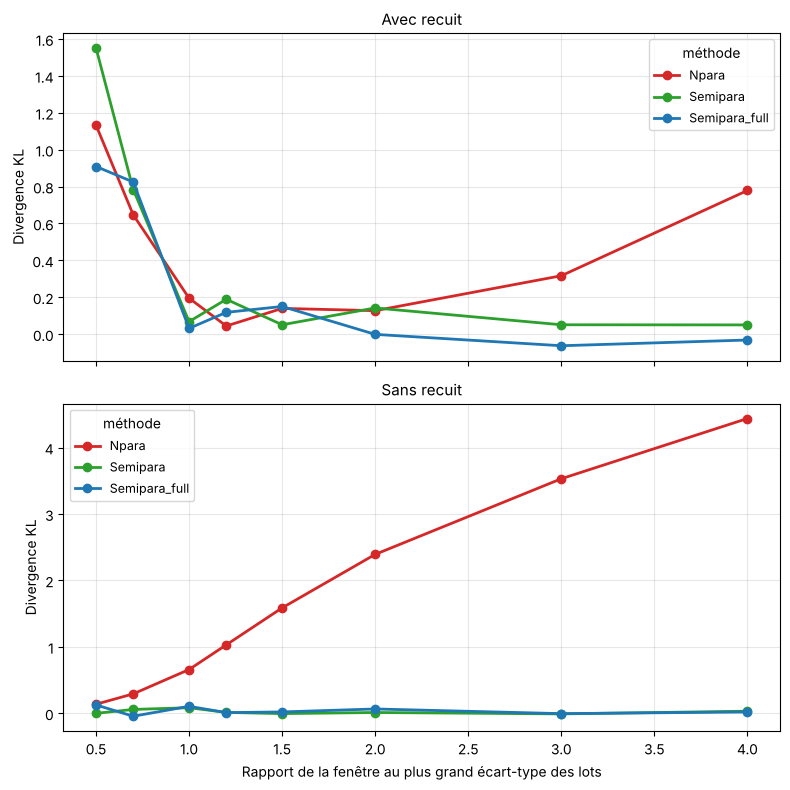

--- Annealed (KL moyenne ± écart-type ; taux d'acceptation des étiquettes)
     ratio |          Npara |       Semipara |  Semipara_full
       0.5 |  1.133±0.217 |  1.551±0.484 |  0.909±0.142
       0.7 |  0.647±0.377 |  0.784±0.491 |  0.825±0.635
       1.0 |  0.195±0.098 |  0.068±0.175 |  0.031±0.113
       1.2 |  0.044±0.063 |  0.189±0.098 |  0.118±0.196
       1.5 |  0.140±0.047 |  0.051±0.119 |  0.150±0.164
       2.0 |  0.127±0.103 |  0.142±0.127 | -0.001±0.130
       3.0 |  0.317±0.034 |  0.051±0.035 | -0.063±0.078
       4.0 |  0.779±0.133 |  0.050±0.014 | -0.032±0.153
   acceptation : {'Npara': [0.035, 0.065, 0.122, 0.166, 0.235, 0.352, 0.545, 0.68], 'Semipara': [0.035, 0.065, 0.123, 0.166, 0.235, 0.35, 0.546, 0.68], 'Semipara_full': [0.035, 0.065, 0.121, 0.164, 0.225, 0.319, 0.413, 0.406]}
--- Not Annealed (KL moyenne ± écart-type ; taux d'acceptation des étiquettes)
     ratio |          Npara |       Semipara |  Semipara_full
       0.5 |  0.137±0.059 | -0.000±0.024 |  0.1

In [22]:
run_figure_3_1()

### Figure 3.2 — Nombre d'observations (méthodes par lots)

10 lots, $10^4$ itérations par lot, $d = 2$, fenêtres initiales $1{,}2\,\sigma_{\max}$ (non paramétrique) et $2\,\sigma_{\max}$ (semi-paramétriques).

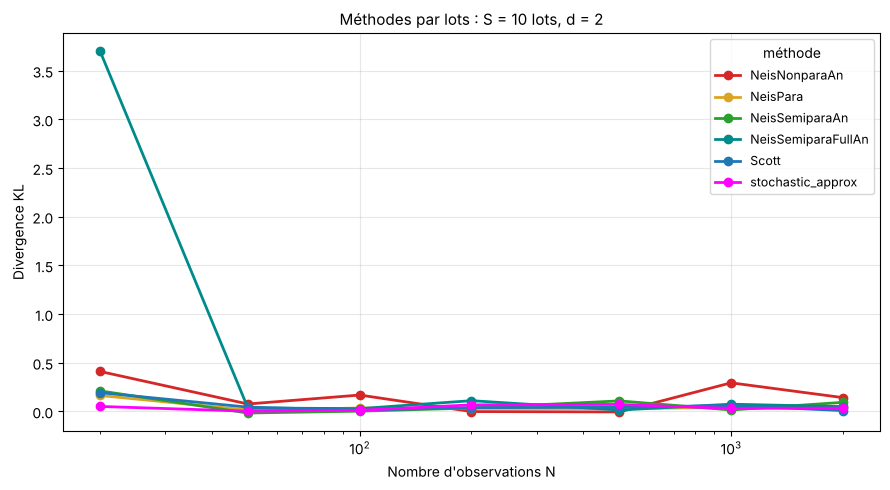

         N |  NeisNonparaAn |       NeisPara | NeisSemiparaAn | NeisSemiparaFu |          Scott | stochastic_app
        20 |  0.411±0.211 |  0.164±0.020 |  0.211±0.078 |  3.701±2.805 |  0.193±0.039 |  0.052±0.014
        50 |  0.077±0.027 |  0.015±0.010 | -0.016±0.019 |  0.036±0.038 |  0.044±0.053 |  0.003±0.023
       100 |  0.169±0.086 |  0.035±0.048 |  0.003±0.003 |  0.029±0.130 |  0.015±0.053 |  0.013±0.016
       200 | -0.001±0.123 |  0.032±0.016 |  0.036±0.120 |  0.111±0.195 |  0.039±0.053 |  0.068±0.024
       500 | -0.005±0.026 |  0.030±0.043 |  0.109±0.003 |  0.015±0.131 |  0.044±0.008 |  0.072±0.017
      1000 |  0.294±0.252 |  0.041±0.038 |  0.015±0.018 |  0.075±0.058 |  0.061±0.017 |  0.032±0.008
      2000 |  0.142±0.028 |  0.052±0.032 |  0.094±0.126 |  0.050±0.164 |  0.009±0.046 |  0.035±0.019
[Fig 3.2] 24 s


In [23]:
run_figure_3_2()

### Figure 3.3 — Taille des lots

800 observations, nombre de lots variable, $10^4$ itérations par lot, $d = 2$.

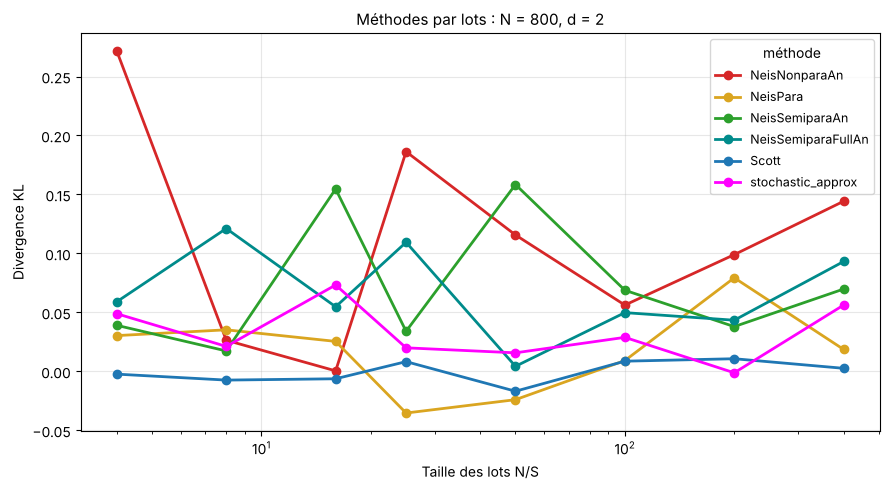

       N/S |  NeisNonparaAn |       NeisPara | NeisSemiparaAn | NeisSemiparaFu |          Scott | stochastic_app
         4 |  0.271±0.169 |  0.030±0.011 |  0.039±0.024 |  0.059±0.034 | -0.002±0.085 |  0.049±0.024
         8 |  0.026±0.048 |  0.035±0.028 |  0.017±0.044 |  0.121±0.050 | -0.007±0.014 |  0.021±0.042
        16 |  0.000±0.061 |  0.025±0.059 |  0.155±0.103 |  0.055±0.043 | -0.006±0.093 |  0.073±0.038
        25 |  0.186±0.121 | -0.035±0.023 |  0.034±0.165 |  0.109±0.110 |  0.008±0.025 |  0.020±0.020
        50 |  0.116±0.059 | -0.024±0.029 |  0.158±0.245 |  0.004±0.072 | -0.017±0.051 |  0.016±0.047
       100 |  0.056±0.130 |  0.009±0.037 |  0.069±0.033 |  0.050±0.079 |  0.009±0.067 |  0.029±0.035
       200 |  0.099±0.088 |  0.079±0.021 |  0.038±0.011 |  0.043±0.062 |  0.011±0.034 | -0.001±0.015
       400 |  0.144±0.040 |  0.019±0.035 |  0.070±0.113 |  0.093±0.099 |  0.003±0.013 |  0.056±0.021
[Fig 3.3] 43 s


In [24]:
run_figure_3_3()

### Figure 3.4 — Dimension (méthodes par lots)

800 observations, 40 lots de 20 observations, $10^4$ itérations. KL entre approximations gaussiennes.

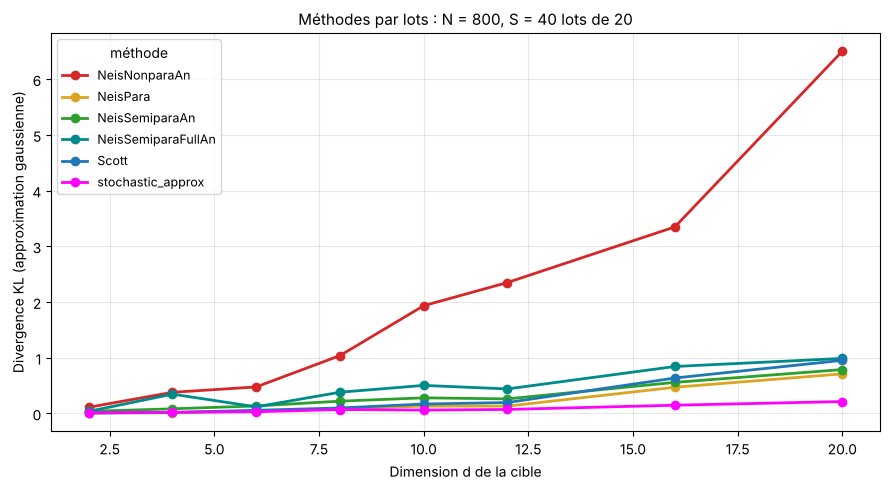

         d |  NeisNonparaAn |       NeisPara | NeisSemiparaAn | NeisSemiparaFu |          Scott | stochastic_app
         2 |  0.111±0.037 |  0.008±0.006 |  0.038±0.011 |  0.038±0.046 |  0.009±0.006 |  0.011±0.003
         4 |  0.380±0.212 |  0.015±0.006 |  0.084±0.008 |  0.347±0.304 |  0.019±0.005 |  0.022±0.006
         6 |  0.477±0.027 |  0.045±0.027 |  0.135±0.007 |  0.119±0.007 |  0.057±0.026 |  0.031±0.015
         8 |  1.039±0.329 |  0.083±0.009 |  0.221±0.030 |  0.382±0.067 |  0.099±0.011 |  0.071±0.021
        10 |  1.935±0.529 |  0.133±0.042 |  0.281±0.040 |  0.504±0.132 |  0.170±0.032 |  0.061±0.008
        12 |  2.351±0.460 |  0.132±0.030 |  0.262±0.022 |  0.441±0.168 |  0.197±0.041 |  0.072±0.039
        16 |  3.349±0.110 |  0.471±0.078 |  0.559±0.083 |  0.844±0.168 |  0.636±0.084 |  0.149±0.019
        20 |  6.503±0.741 |  0.711±0.088 |  0.788±0.083 |  0.988±0.077 |  0.954±0.083 |  0.214±0.027
[Fig 3.4] 56 s


In [25]:
run_figure_3_4()

### Calibrage des méthodes de gradient stochastique

La constante $a$ de SGLD et le couple $(\gamma, \alpha)$ de SGHMC ($L = 10$) sont choisis en minimisant la KL par rapport à MH ($N = 10^4$, $d = 2$, $n = 100$, 3 graines).

In [26]:
run_calibration()

SGLD  : KL moyenne selon a : {0.1: 1.783, 0.5: 0.315, 1: 0.145, 2: 0.01, 5: 0.235, 10: 0.834, 20: 1.461}
SGHMC : KL moyenne (lignes γ, colonnes α) :
        α = (0.01, 0.05, 0.1, 0.5)
  γ = 0.01  [ 0.02   0.241 -0.024  0.119]
  γ = 0.05  [0.967 0.736 0.628 0.139]
  γ = 0.1   [1.938 1.616 1.353 0.384]
  γ = 0.5   [5.806 5.102 4.517 2.252]
==> retenu : a = 2.0 ; γ = 0.01, α = 0.1, L = 10
[Calibrage] 67 s


### Figure 3.5 — Taille du sous-échantillon

$N = 10^5$ observations, burn-in de $10^3$ puis $10^4$ itérations, $d = 2$.

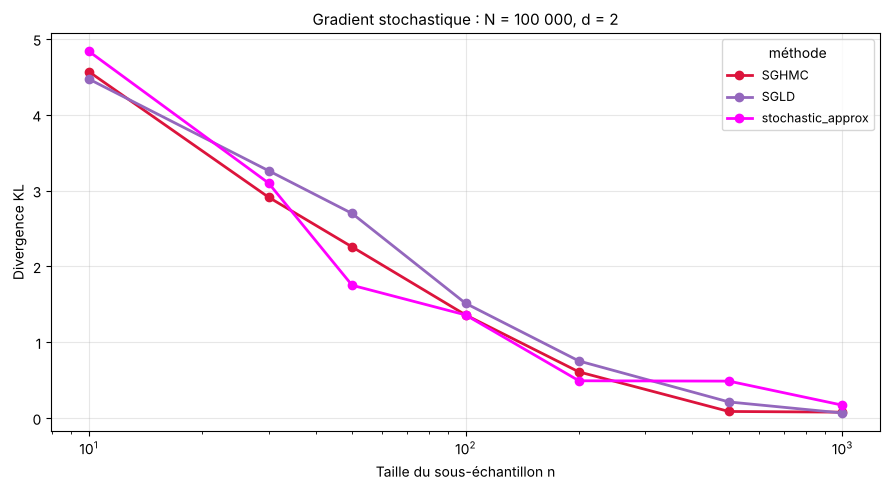

         n |          SGHMC |           SGLD | stochastic_app
        10 |  4.569±0.107 |  4.471±0.142 |  4.837±2.199
        30 |  2.912±0.059 |  3.262±0.145 |  3.099±1.827
        50 |  2.256±0.138 |  2.697±0.029 |  1.750±0.460
       100 |  1.359±0.129 |  1.513±0.334 |  1.359±0.890
       200 |  0.607±0.088 |  0.751±0.258 |  0.490±0.256
       500 |  0.086±0.109 |  0.211±0.060 |  0.486±0.189
      1000 |  0.077±0.045 |  0.065±0.131 |  0.169±0.140
[Fig 3.5] 357 s


In [27]:
run_figure_3_5()

### Figure 3.6 — Nombre d'observations (gradient stochastique)

Sous-échantillon $n = 10$, burn-in de $10^3$ puis $10^4$ itérations, $d = 2$ ; Scott avec 10 lots.

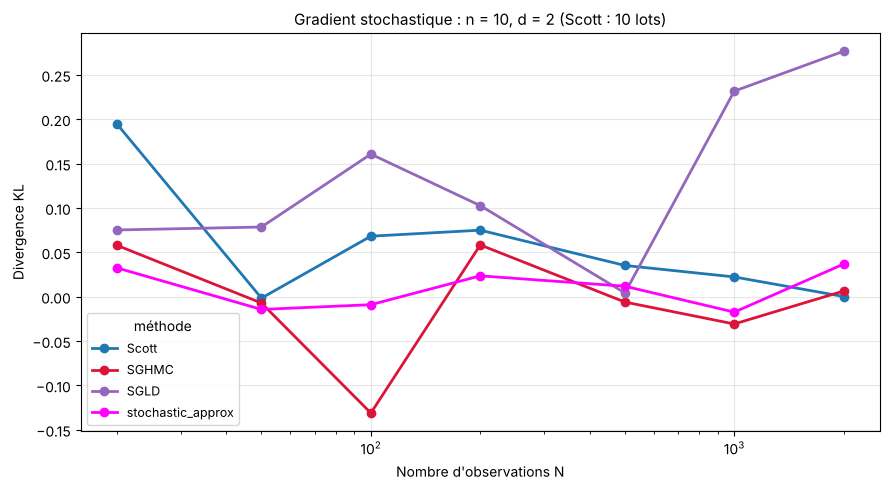

         N |          Scott |          SGHMC |           SGLD | stochastic_app
        20 |  0.195±0.134 |  0.058±0.120 |  0.075±0.056 |  0.033±0.040
        50 | -0.002±0.055 | -0.007±0.098 |  0.079±0.117 | -0.014±0.045
       100 |  0.068±0.015 | -0.131±0.078 |  0.161±0.033 | -0.009±0.060
       200 |  0.075±0.069 |  0.058±0.180 |  0.103±0.124 |  0.024±0.025
       500 |  0.035±0.003 | -0.006±0.089 |  0.004±0.103 |  0.012±0.015
      1000 |  0.022±0.027 | -0.031±0.065 |  0.232±0.218 | -0.017±0.011
      2000 |  0.000±0.048 |  0.006±0.058 |  0.277±0.236 |  0.037±0.030
[Fig 3.6] 23 s


In [28]:
run_figure_3_6()

### Figure 3.7 — Dimension (gradient stochastique)

800 observations, $n = 200$ ; Scott avec 40 lots de 20. KL entre approximations gaussiennes.

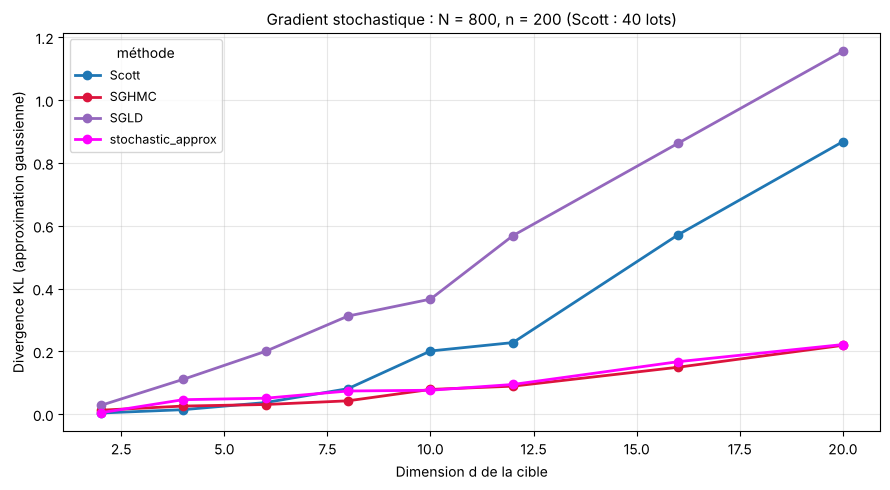

         d |          Scott |          SGHMC |           SGLD | stochastic_app
         2 |  0.004±0.003 |  0.013±0.006 |  0.028±0.004 |  0.004±0.002
         4 |  0.014±0.009 |  0.026±0.008 |  0.111±0.044 |  0.046±0.012
         6 |  0.037±0.008 |  0.031±0.008 |  0.200±0.021 |  0.051±0.018
         8 |  0.081±0.027 |  0.043±0.006 |  0.312±0.080 |  0.074±0.032
        10 |  0.201±0.004 |  0.079±0.009 |  0.366±0.073 |  0.076±0.018
        12 |  0.228±0.055 |  0.089±0.004 |  0.568±0.075 |  0.095±0.012
        16 |  0.571±0.149 |  0.149±0.007 |  0.862±0.150 |  0.167±0.059
        20 |  0.868±0.069 |  0.219±0.009 |  1.155±0.064 |  0.222±0.044
[Fig 3.7] 52 s


In [29]:
run_figure_3_7()

In [30]:
import json
with open(os.path.join(OUTPUT_DIR, "results_chapitre3.json"), "w") as f:
    json.dump(RESULTS, f, default=float)
print("Résultats enregistrés.")

Résultats enregistrés.
